# Visualisasi — Kualitas Data (missing, outlier, duplikat, drift)
**Kapan dipakai:** "datanya bersih? ada yang bolong, aneh, kembar, atau beda antara train dan
test?"

**Isi:** matriks missing (tanpa missingno), % missing per kolom, missing vs target, outlier (box
diskala IQR), duplikat, kardinalitas kategori, drift train vs test (KDE + PSI).
Semua gambar disimpan di folder notebook.

**Data demo:** Titanic (missing), California housing (outlier, drift), Online Retail (duplikat).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan"   # GANTI saat lomba
TITANIC_CSV = f"{DATA_FOLDER}/tabular/classification/titanic_train.csv"
GEO_TRAIN_CSV = f"{DATA_FOLDER}/tabular_extra/geo/california_train.csv"
GEO_TEST_CSV = f"{DATA_FOLDER}/tabular_extra/geo/california_test.csv"
RETAIL_CSV = f"{DATA_FOLDER}/unsupervised/online_retail.csv"

TARGET = "survived"
GEO_NUMBER_COLS = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup"]

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Baca data

In [4]:
titanic = pd.read_csv(TITANIC_CSV)
geo_train = pd.read_csv(GEO_TRAIN_CSV)
geo_test = pd.read_csv(GEO_TEST_CSV)
retail = pd.read_csv(RETAIL_CSV)
print(titanic.shape, geo_train.shape, geo_test.shape, retail.shape)
missing_counts = titanic.isna().sum()
missing_counts[missing_counts > 0]

(712, 16) (6000, 10) (2000, 9) (165225, 8)


age            137
embarked         2
deck           553
embark_town      2
dtype: int64

## 1. Matriks missing
**Kapan dipakai:** langkah pertama EDA, melihat letak dan pola nilai hilang.
**Cara baca:** tiap baris = satu data, tiap kolom = satu fitur, garis gelap = nilai hilang.
Kolom yang hilangnya serempak (pola sama) kemungkinan berasal dari sebab yang sama.

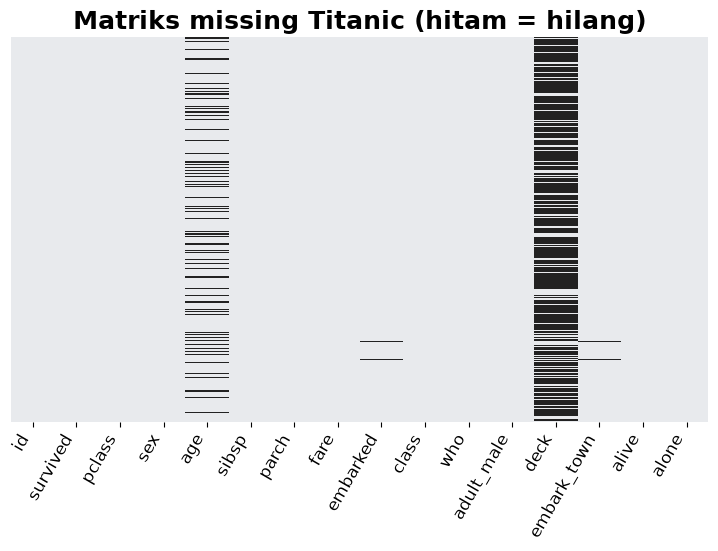

In [5]:
plt.figure(figsize=(9, 5))
sns.heatmap(titanic.isna(), cbar=False, yticklabels=False, cmap=["#E8EAED", "#222222"])
plt.title("Matriks missing Titanic (hitam = hilang)")
plt.xticks(rotation=60, ha="right")
plt.grid(False)
# Alternatif urut per pola missing: titanic.sort_values(["deck", "age"]).isna()
plt.savefig("kualitas_matriks_missing.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Persen missing per kolom
**Kapan dipakai:** memutuskan kolom mana dibuang (> 50% hilang), diimputasi, atau diberi
indikator "hilang". **Cara baca:** bar oranye lewat garis 5%, merah lewat 50%.

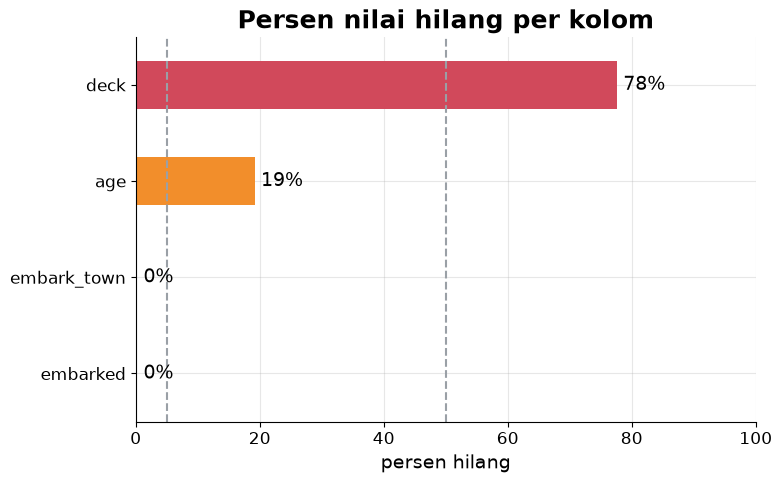

In [6]:
missing_percent = titanic.isna().mean() * 100
missing_percent = missing_percent[missing_percent > 0]
missing_percent = missing_percent.sort_values()
colors = []
for value in missing_percent:
    if value > 50:
        colors.append(RED)
    elif value > 5:
        colors.append(ORANGE)
    else:
        colors.append(BLUE)
missing_percent.plot.barh(color=colors)
plt.axvline(5, color=GREY, linestyle="--")
plt.axvline(50, color=GREY, linestyle="--")
for i, value in enumerate(missing_percent):
    plt.text(value, i, f" {value:.0f}%", va="center")
plt.title("Persen nilai hilang per kolom")
plt.xlabel("persen hilang")
plt.xlim(0, 100)
plt.savefig("kualitas_persen_missing.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Apakah hilang itu informatif? (missing vs target)
**Kapan dipakai:** sebelum imputasi. Kadang "hilang" itu sendiri sinyal (mis. tanpa kabin =
kelas murah). **Cara baca:** kalau dua bar sangat berbeda, tambahkan kolom indikator
`kolom_hilang`.

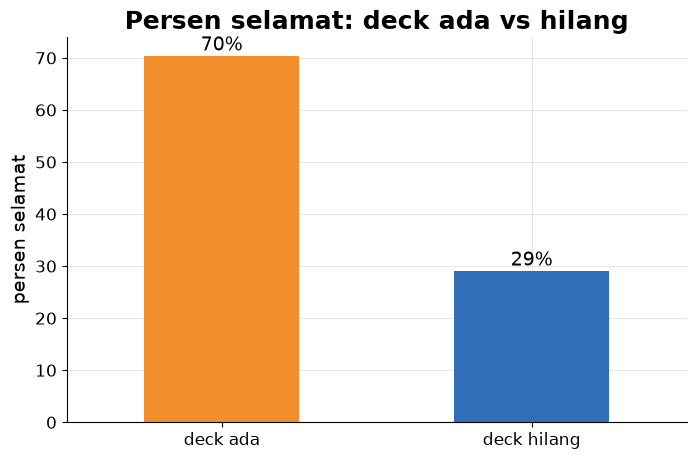

In [7]:
deck_missing = titanic["deck"].isna().map({True: "deck hilang", False: "deck ada"})
survival_rate = titanic.groupby(deck_missing)[TARGET].mean() * 100
survival_rate.plot.bar(color=[ORANGE, BLUE], rot=0)
for i, value in enumerate(survival_rate):
    plt.text(i, value + 1, f"{value:.0f}%", ha="center")
plt.title("Persen selamat: deck ada vs hilang")
plt.xlabel("")
plt.ylabel("persen selamat")
plt.savefig("kualitas_missing_vs_target.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Outlier (box diskala IQR)
**Kapan dipakai:** banyak kolom dengan satuan berbeda, ingin membandingkan keanehan sekaligus.
**Cara baca:** tiap kolom dikurangi median lalu dibagi IQR. Titik di luar kumis = kandidat
outlier, makin jauh makin ekstrem. Cek apakah itu kesalahan input atau data nyata.

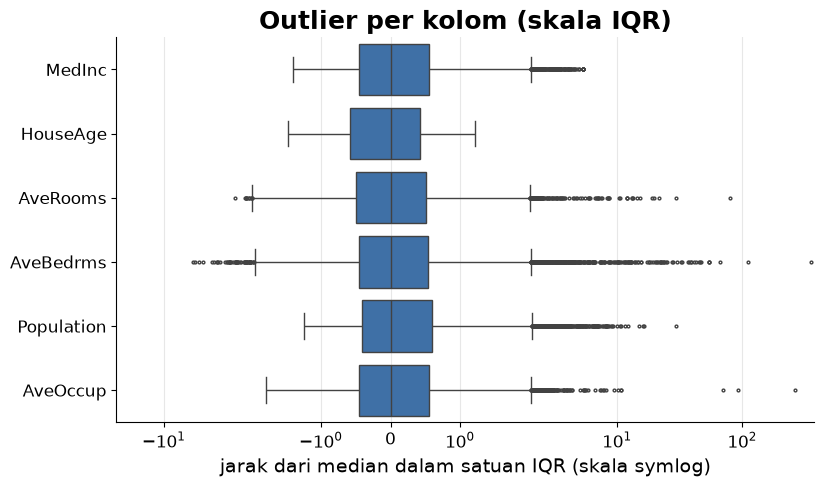

In [8]:
numbers = geo_train[GEO_NUMBER_COLS]
iqr = numbers.quantile(0.75) - numbers.quantile(0.25)
scaled = (numbers - numbers.median()) / iqr
plt.figure(figsize=(9, 5))
sns.boxplot(data=scaled, orient="h", color=BLUE, fliersize=2)
plt.xscale("symlog")
plt.title("Outlier per kolom (skala IQR)")
plt.xlabel("jarak dari median dalam satuan IQR (skala symlog)")
# Alternatif jumlah outlier: ((numbers < q1 - 1.5 * iqr) | (numbers > q3 + 1.5 * iqr)).mean()
plt.savefig("kualitas_outlier_box.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Duplikat
**Kapan dipakai:** sebelum split train/validasi (duplikat lintas split = bocor).
**Cara baca:** bagian oranye = baris yang sama persis dengan baris lain.

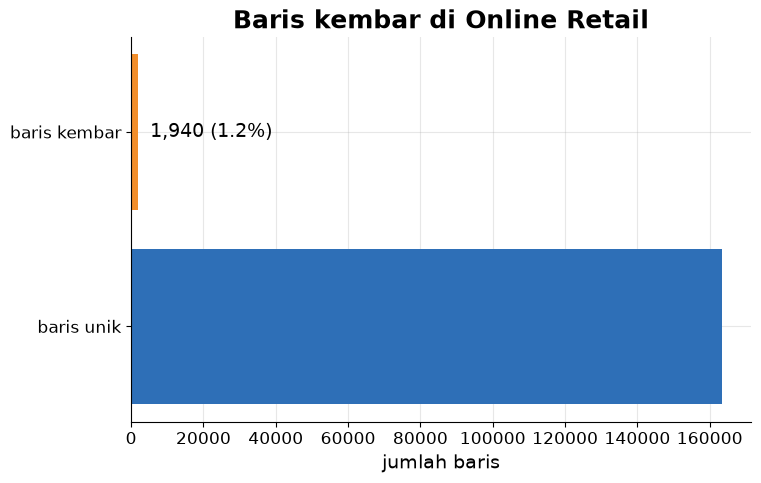

In [9]:
duplicate_count = retail.duplicated().sum()
unique_count = len(retail) - duplicate_count
plt.barh(["baris unik", "baris kembar"], [unique_count, duplicate_count], color=[BLUE, ORANGE])
duplicate_share = duplicate_count / len(retail)
plt.text(duplicate_count, 1, f"  {duplicate_count:,} ({duplicate_share:.1%})", va="center")
plt.title("Baris kembar di Online Retail")
plt.xlabel("jumlah baris")
# Alternatif kembar tanpa kolom ID: titanic.duplicated(subset=titanic.columns.drop("id")).sum()
plt.savefig("kualitas_duplikat.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Kardinalitas kategori
**Kapan dipakai:** memilih cara encoding (one-hot cocok untuk <= 20 nilai unik, target/frequency
encoding untuk banyak nilai). **Cara baca:** bar merah = hampir unik tiap baris (mirip ID).

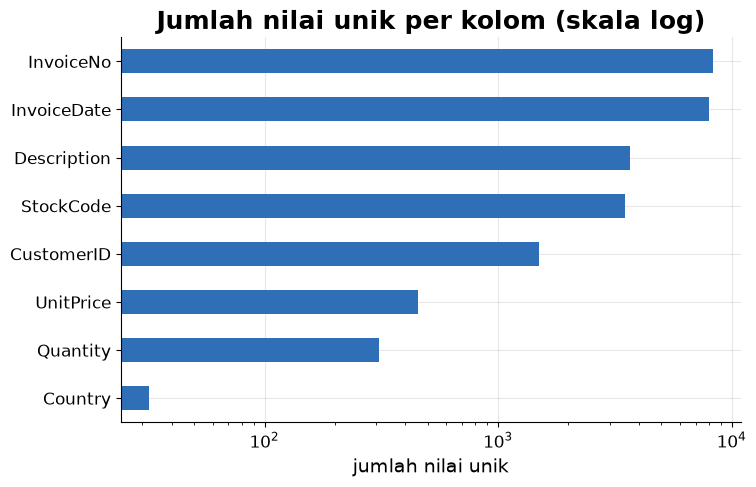

In [10]:
unique_values = retail.nunique().sort_values()
colors = []
for value in unique_values:
    if value > 0.5 * len(retail):
        colors.append(RED)    # hampir unik per baris, mirip ID
    else:
        colors.append(BLUE)
unique_values.plot.barh(color=colors)
plt.xscale("log")
plt.title("Jumlah nilai unik per kolom (skala log)")
plt.xlabel("jumlah nilai unik")
plt.savefig("kualitas_kardinalitas.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Drift train vs test (KDE dan PSI)
**Kapan dipakai:** memastikan test mirip train. Kalau beda, validasi lokal tidak mewakili.
**Cara baca:** PSI < 0.1 aman, 0.1-0.25 waspada, > 0.25 bergeser jauh. Dua kurva KDE yang
saling menimpa = sebaran sama.

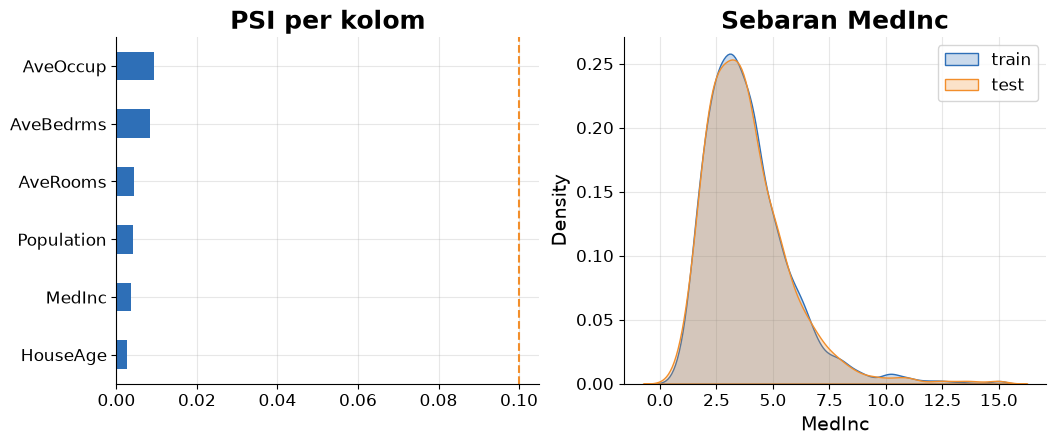

In [11]:
def psi(old, new, bins=10):
    # PSI = seberapa jauh sebaran baru bergeser dari sebaran lama (dibagi per desil lama)
    edges = np.unique(np.quantile(old, np.linspace(0, 1, bins + 1)))
    old_share = np.histogram(old, edges)[0] / len(old) + 1e-4
    new_clipped = np.clip(new, edges[0], edges[-1])
    new_share = np.histogram(new_clipped, edges)[0] / len(new) + 1e-4
    return np.sum((old_share - new_share) * np.log(old_share / new_share))


psi_values = pd.Series(dtype=float)
for column in GEO_NUMBER_COLS:
    psi_values[column] = psi(geo_train[column], geo_test[column])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
psi_values.sort_values().plot.barh(color=BLUE, ax=axes[0])
axes[0].axvline(0.1, color=ORANGE, linestyle="--")
axes[0].set_title("PSI per kolom")
sns.kdeplot(geo_train["MedInc"], label="train", color=BLUE, fill=True, ax=axes[1])
sns.kdeplot(geo_test["MedInc"], label="test", color=ORANGE, fill=True, ax=axes[1])
axes[1].set_title("Sebaran MedInc")
axes[1].legend()
# Alternatif uji statistik: scipy.stats.ks_2samp(geo_train["MedInc"], geo_test["MedInc"])
plt.savefig("kualitas_drift.png", dpi=200, bbox_inches="tight")
plt.show()